In [1]:
# Global Space Missions: Environmental Impact Analysis and Prediction 
# Introduction to Data Science Lab Project

#Domain: Space Exploration  
#Project Type: Data Analysis and Machine Learning Classification

 ## 2. Introduction

Space exploration involves a wide range of missions carried out by different countries using different technologies, mission types, launch sites, and satellite systems. These missions also vary in budget, success rate, duration, and environmental impact.

#In this project, a global space mission dataset is analyzed using Python and Data Science techniques. The analysis focuses on understanding the characteristics of space missions and identifying patterns and relationships associated with their environmental impact.

After exploring and preprocessing the data, machine learning classification techniques are applied to predict the environmental impact category of a space mission.

The target variable used in this project is **Environmental Impact**, which is classified into three categories: **Low, Medium, and High**.

## 2.1 Problem Statement

The environmental impact associated with space missions may vary depending on different mission characteristics. Analyzing a large collection of space mission records manually can make it difficult to identify patterns and relationships.

Therefore, this project aims to analyze space mission data and develop a machine learning classification model that can predict the environmental impact category of a mission.

## 2.2 Aim

To analyze global space mission data and develop a machine learning model for predicting the environmental impact of space missions.

## 2.3 Objectives

The objectives of this project are:

1. To load and understand the global space mission dataset.
2. To examine the structure, variables, and statistical characteristics of the dataset.
3. To check the dataset for missing values, duplicate records, and data-quality issues.
4. To analyze the distribution of the target variable, Environmental Impact.
5. To perform Exploratory Data Analysis (EDA) using statistical methods and visualizations.
6. To analyze relationships between numerical variables using correlation analysis.
7. To select appropriate features and the target variable for machine learning.
8. To preprocess numerical and categorical data.
9. To train multiple classification models.
10. To compare Logistic Regression, Decision Tree, Random Forest, and K-Nearest Neighbors (KNN).
11. To evaluate the performance of the classification models.
12. To select the best-performing model for predicting Environmental Impact.
13. To interpret the model results and identify important features.
14. To summarize the findings and limitations of the project.

## 2.4 Machine Learning Problem

This project is a **supervised machine learning classification problem**.

The model uses space mission characteristics as input features and predicts the Environmental Impact category as the output.

**Input:** Space mission characteristics

**Output:** Environmental Impact

- High
- Medium
- Low


In [2]:


# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine Learning classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [3]:
#  Load Dataset

df = pd.read_csv("../data/Global_Space_Exploration_Dataset.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
df.head()

,Country,Year,Mission Name,Mission Type,Launch Site,Satellite Type,Budget (in Billion $),Success Rate (%),Technology Used,Environmental Impact,Collaborating Countries,Duration (in Days)
0,China,2008,Sharable tertiary superstructure,Manned,Sheilatown,Communication,16.20,90,Nuclear Propulsion,Medium,"France, UK, Russia",112
1,Japan,2018,Re-engineered composite flexibility,Manned,New Ericfurt,Communication,29.04,99,Solar Propulsion,High,"Germany, Israel",236
2,Israel,2013,Reactive disintermediate projection,Manned,Port Kaitlynstad,Communication,28.73,54,AI Navigation,Medium,"China, Israel, USA",238
3,UAE,2010,Grass-roots 6thgeneration implementation,Unmanned,Mariastad,Spy,37.27,58,Traditional Rocket,Low,USA,186
4,India,2006,Balanced discrete orchestration,Manned,North Jasonborough,Weather,18.95,91,Solar Propulsion,Medium,"Israel, China, India",277


In [5]:
df.shape

(3000, 12)

In [6]:
type(df)

pandas.DataFrame

In [7]:
df.columns.tolist()

['Country',
 'Year',
 'Mission Name',
 'Mission Type',
 'Launch Site',
 'Satellite Type',
 'Budget (in Billion $)',
 'Success Rate (%)',
 'Technology Used',
 'Environmental Impact',
 'Collaborating Countries',
 'Duration (in Days)']

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Country                  3000 non-null   str    
 1   Year                     3000 non-null   int64  
 2   Mission Name             3000 non-null   str    
 3   Mission Type             3000 non-null   str    
 4   Launch Site              3000 non-null   str    
 5   Satellite Type           3000 non-null   str    
 6   Budget (in Billion $)    3000 non-null   float64
 7   Success Rate (%)         3000 non-null   int64  
 8   Technology Used          3000 non-null   str    
 9   Environmental Impact     3000 non-null   str    
 10  Collaborating Countries  3000 non-null   str    
 11  Duration (in Days)       3000 non-null   int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 281.4 KB


In [9]:
df.describe()

,Year,Budget (in Billion $),Success Rate (%),Duration (in Days)
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,2012.471000,25.428917,74.985000,181.483000
std,7.437177,14.108438,14.945252,104.983822
min,2000.000000,0.530000,50.000000,1.000000
25%,2006.000000,12.977500,62.000000,91.000000
50%,2012.000000,25.495000,75.000000,180.000000
75%,2019.000000,37.597500,88.000000,272.000000
max,2025.000000,49.970000,100.000000,365.000000


In [10]:
 #step 6: Data Quality Check
import pandas as pd

In [11]:
df = pd.read_csv("../data/Global_Space_Exploration_Dataset.csv")

print("Dataset loaded successfully.")


Dataset loaded successfully.


In [12]:
df.head()

,Country,Year,Mission Name,Mission Type,Launch Site,Satellite Type,Budget (in Billion $),Success Rate (%),Technology Used,Environmental Impact,Collaborating Countries,Duration (in Days)
0,China,2008,Sharable tertiary superstructure,Manned,Sheilatown,Communication,16.20,90,Nuclear Propulsion,Medium,"France, UK, Russia",112
1,Japan,2018,Re-engineered composite flexibility,Manned,New Ericfurt,Communication,29.04,99,Solar Propulsion,High,"Germany, Israel",236
2,Israel,2013,Reactive disintermediate projection,Manned,Port Kaitlynstad,Communication,28.73,54,AI Navigation,Medium,"China, Israel, USA",238
3,UAE,2010,Grass-roots 6thgeneration implementation,Unmanned,Mariastad,Spy,37.27,58,Traditional Rocket,Low,USA,186
4,India,2006,Balanced discrete orchestration,Manned,North Jasonborough,Weather,18.95,91,Solar Propulsion,Medium,"Israel, China, India",277


In [13]:
df.isnull().sum()


Country                    0
Year                       0
Mission Name               0
Mission Type               0
Launch Site                0
Satellite Type             0
Budget (in Billion $)      0
Success Rate (%)           0
Technology Used            0
Environmental Impact       0
Collaborating Countries    0
Duration (in Days)         0
dtype: int64

In [14]:
# Step 6.2: Check duplicate rows

df.duplicated().sum()

np.int64(0)

In [15]:
# Step 6.3: Check data types

df.dtypes

Country                        str
Year                         int64
Mission Name                   str
Mission Type                   str
Launch Site                    str
Satellite Type                 str
Budget (in Billion $)      float64
Success Rate (%)             int64
Technology Used                str
Environmental Impact           str
Collaborating Countries        str
Duration (in Days)           int64
dtype: object

In [16]:
# Step 6.4: Overall Data Quality Check

print("Dataset Shape:", df.shape)

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("Total Duplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (3000, 12)

Total Missing Values: 0
Total Duplicate Rows: 0

Data Types:
Country                        str
Year                         int64
Mission Name                   str
Mission Type                   str
Launch Site                    str
Satellite Type                 str
Budget (in Billion $)      float64
Success Rate (%)             int64
Technology Used                str
Environmental Impact           str
Collaborating Countries        str
Duration (in Days)           int64
dtype: object


In [17]:
#step 7: target analysis 
 # Step 7.1: Define target category order

target_order = ["High", "Medium", "Low"]

print("Target Categories:")
for category in target_order:
    print(category)

Target Categories:
High
Medium
Low


In [18]:
# Step 7.2: Target frequency

target_counts = (
    df["Environmental Impact"]
    .value_counts()
    .reindex(target_order)
)

target_counts

Environmental Impact
High       958
Medium    1032
Low       1010
Name: count, dtype: int64

In [19]:
# Step 7.3: Target percentages

target_percentages = (
    df["Environmental Impact"]
    .value_counts(normalize=True)
    .reindex(target_order)
    * 100
)

target_percentages.round(2)

Environmental Impact
High      31.93
Medium    34.40
Low       33.67
Name: proportion, dtype: float64

In [20]:
#Step 7.4: Target Distribution

import matplotlib.pyplot as plt
import seaborn as sns

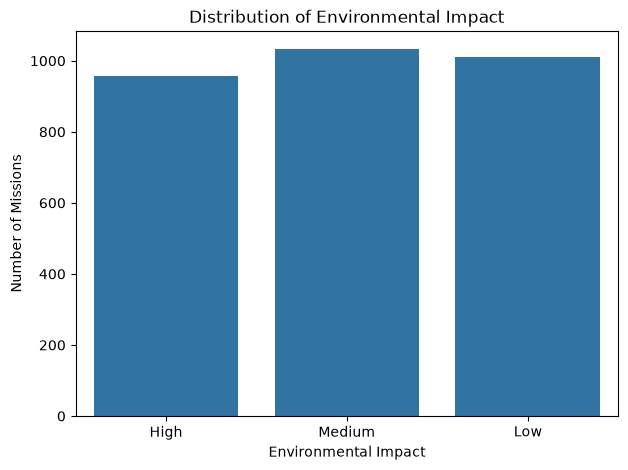

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Environmental Impact",
    order=target_order
)

plt.title("Distribution of Environmental Impact")
plt.xlabel("Environmental Impact")
plt.ylabel("Number of Missions")

plt.show()

In [22]:
# Step 7.5: Target Summary Table

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

target_summary

,Count,Percentage
Environmental Impact,,
High,958,31.93
Medium,1032,34.40
Low,1010,33.67


In [23]:
# Step 8: EDA

import pandas as pd
import numpy as np

df = pd.read_csv("../data/Global_Space_Exploration_Dataset.csv")

print("Dataset loaded successfully.")
print(df.describe)
print(df.head)

Dataset loaded successfully.
<bound method NDFrame.describe of      Country  Year                                 Mission Name Mission Type  \
0      China  2008             Sharable tertiary superstructure       Manned   
1      Japan  2018          Re-engineered composite flexibility       Manned   
2     Israel  2013          Reactive disintermediate projection       Manned   
3        UAE  2010     Grass-roots 6thgeneration implementation     Unmanned   
4      India  2006              Balanced discrete orchestration       Manned   
...      ...   ...                                          ...          ...   
2995   China  2023                Synergistic scalable intranet       Manned   
2996  France  2009           Team-oriented value-added extranet       Manned   
2997   India  2020              Face-to-face even-keeled matrix     Unmanned   
2998  Russia  2002               Open-source secondary software       Manned   
2999   Japan  2014  Public-key cohesive artificial intell

In [24]:
# Step 8.1: Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
['Year', 'Budget (in Billion $)', 'Success Rate (%)', 'Duration (in Days)']


In [25]:
 #8.2 Categorical Data Analysis
import matplotlib.pyplot as plt
import seaborn as sns

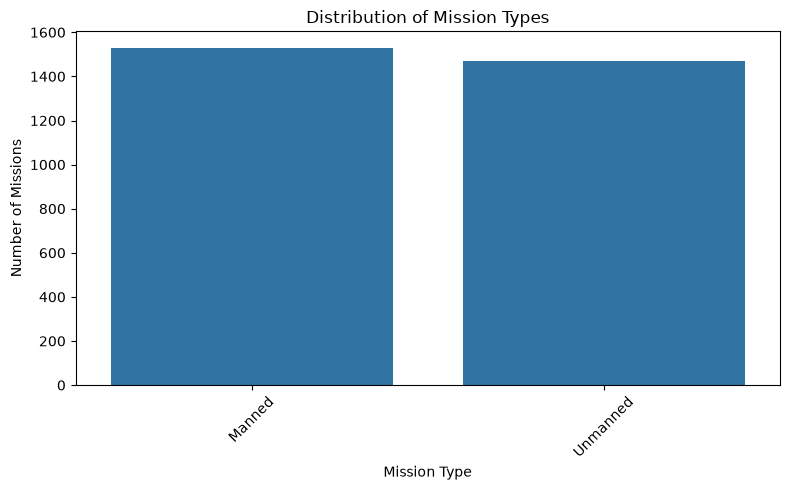

In [26]:
# Step 8.2.1: Mission Type Distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Mission Type")

plt.title("Distribution of Mission Types")
plt.xlabel("Mission Type")
plt.ylabel("Number of Missions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

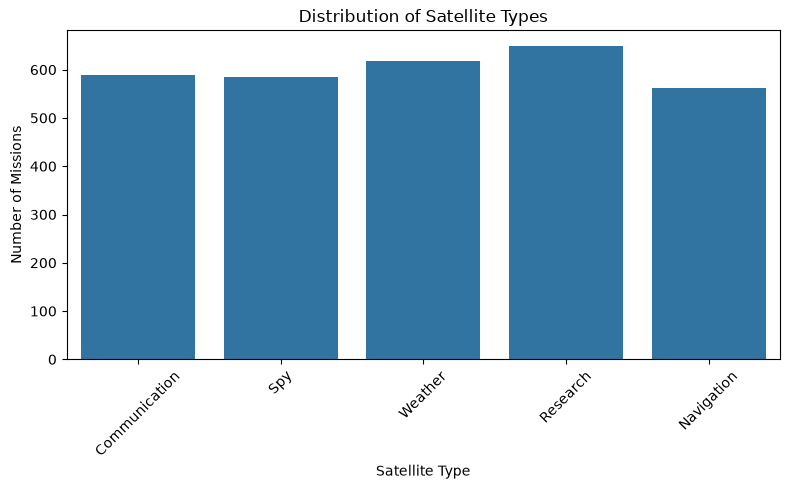

In [27]:
# Step 8.2.2: Satellite Type Distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Satellite Type")

plt.title("Distribution of Satellite Types")
plt.xlabel("Satellite Type")
plt.ylabel("Number of Missions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

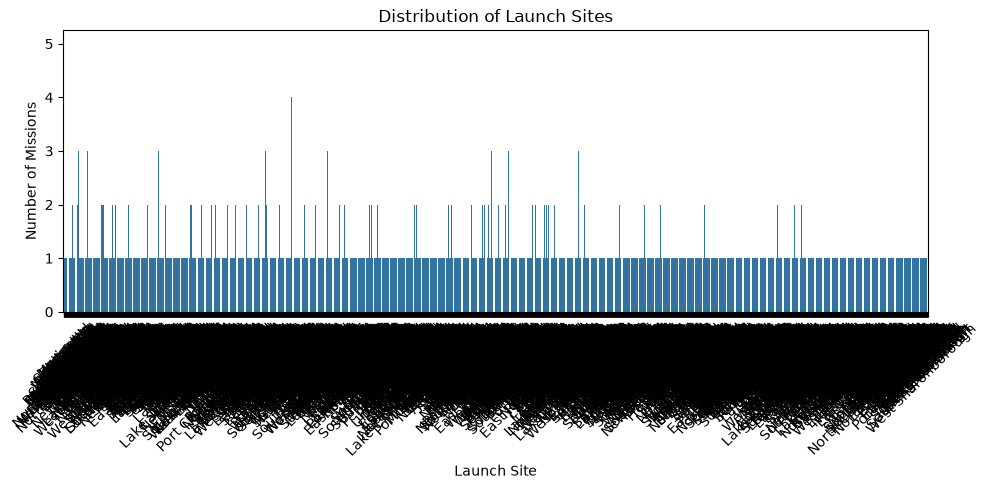

In [28]:
# Step 8.2.3.1: Launch Site Distribution

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Launch Site")

plt.title("Distribution of Launch Sites")
plt.xlabel("Launch Site")
plt.ylabel("Number of Missions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

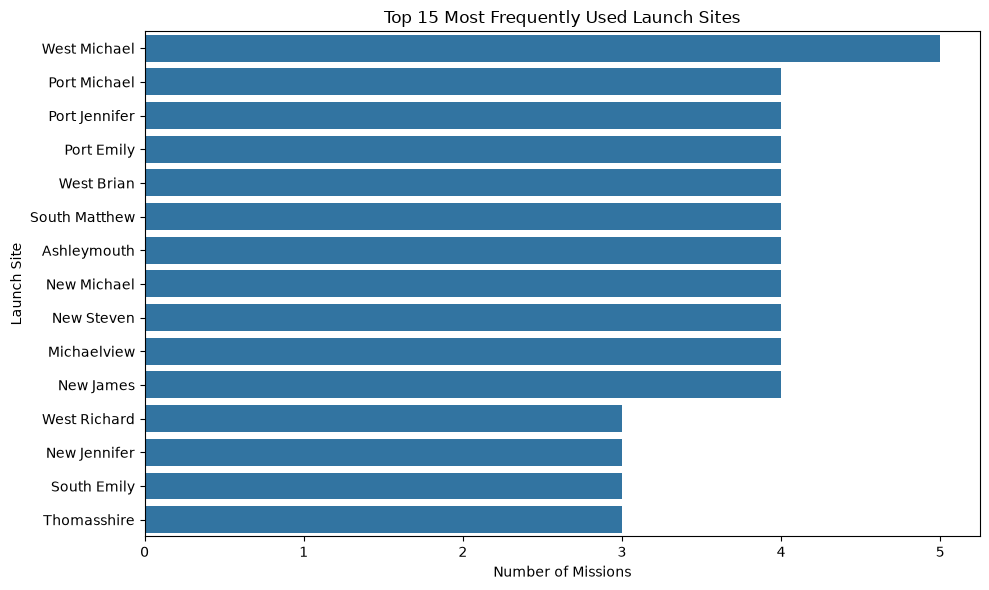

In [29]:
# Step 8.2.3.2: Top 15 Launch Sites

top_launch_sites = df["Launch Site"].value_counts().head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_launch_sites.values,
    y=top_launch_sites.index
)

plt.title("Top 15 Most Frequently Used Launch Sites")
plt.xlabel("Number of Missions")
plt.ylabel("Launch Site")

plt.tight_layout()
plt.show()

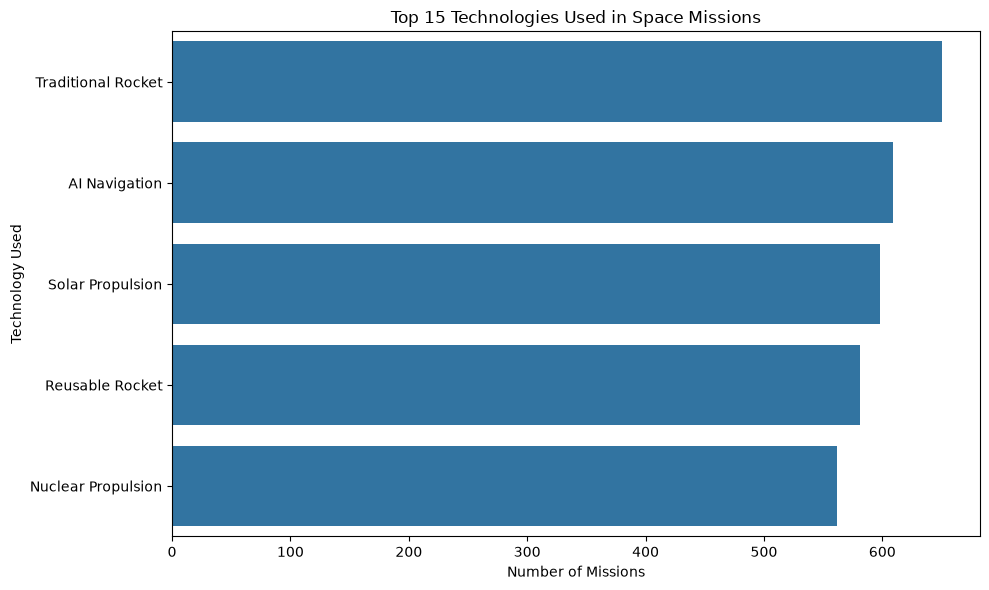

In [30]:
# Step 8.2.4: Technology Used Distribution

plt.figure(figsize=(10, 6))

top_technologies = df["Technology Used"].value_counts().head(15)

sns.barplot(
    x=top_technologies.values,
    y=top_technologies.index
)

plt.title("Top 15 Technologies Used in Space Missions")
plt.xlabel("Number of Missions")
plt.ylabel("Technology Used")

plt.tight_layout()
plt.show()

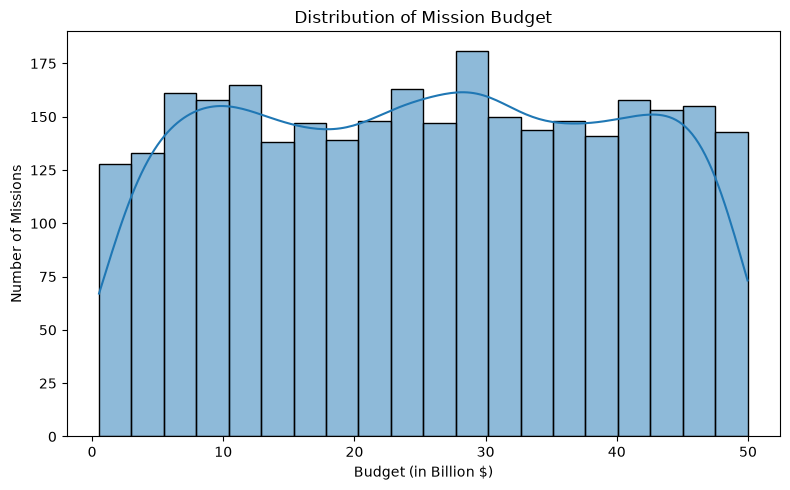

In [31]:
# Step 8.3.1: Budget Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Budget (in Billion $)",
    bins=20,
    kde=True
)

plt.title("Distribution of Mission Budget")
plt.xlabel("Budget (in Billion $)")
plt.ylabel("Number of Missions")

plt.tight_layout()
plt.show()

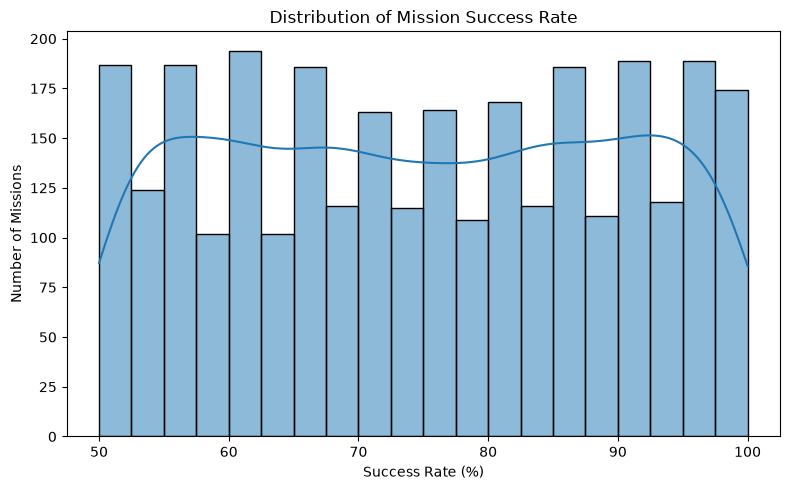

In [32]:
# Step 8.3.2: Success Rate Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Success Rate (%)",
    bins=20,
    kde=True
)

plt.title("Distribution of Mission Success Rate")
plt.xlabel("Success Rate (%)")
plt.ylabel("Number of Missions")

plt.tight_layout()
plt.show()

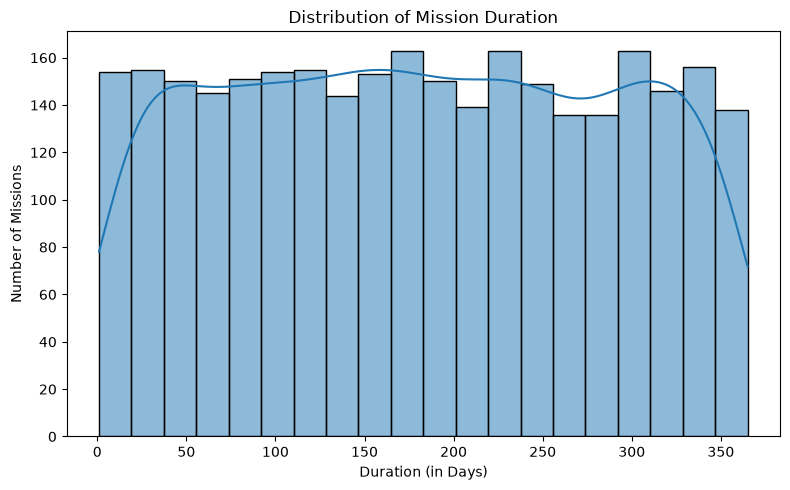

In [33]:
# Step 8.3.3: Mission Duration Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Duration (in Days)",
    bins=20,
    kde=True
)

plt.title("Distribution of Mission Duration")
plt.xlabel("Duration (in Days)")
plt.ylabel("Number of Missions")

plt.tight_layout()
plt.show()

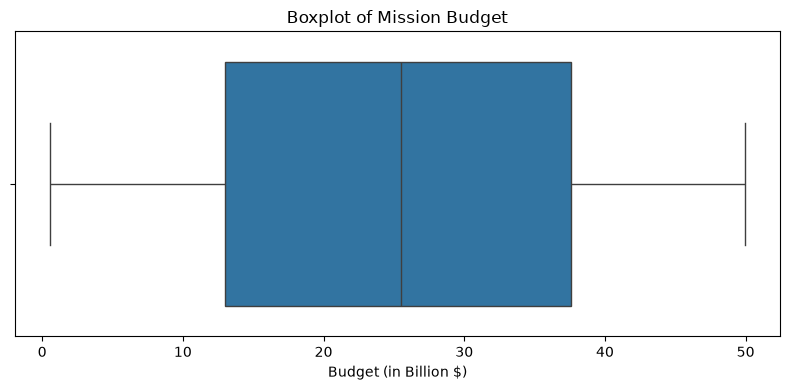

In [34]:
# Step 8.4.1: Budget Boxplot

plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="Budget (in Billion $)")

plt.title("Boxplot of Mission Budget")
plt.xlabel("Budget (in Billion $)")

plt.tight_layout()
plt.show()

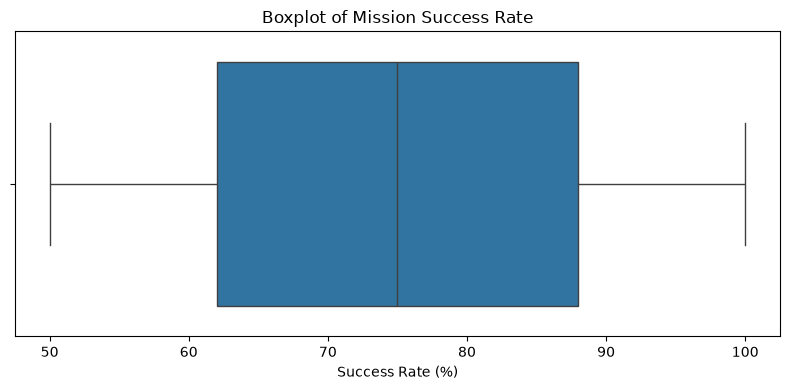

In [35]:
# Step 8.4.2: Success Rate Boxplot

plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="Success Rate (%)")

plt.title("Boxplot of Mission Success Rate")
plt.xlabel("Success Rate (%)")

plt.tight_layout()
plt.show()

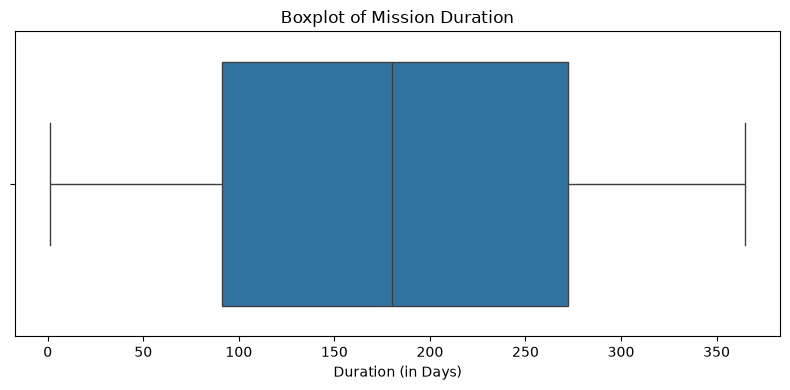

In [36]:
# Step 8.4.3: Mission Duration Boxplot

plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x="Duration (in Days)")

plt.title("Boxplot of Mission Duration")
plt.xlabel("Duration (in Days)")

plt.tight_layout()
plt.show()

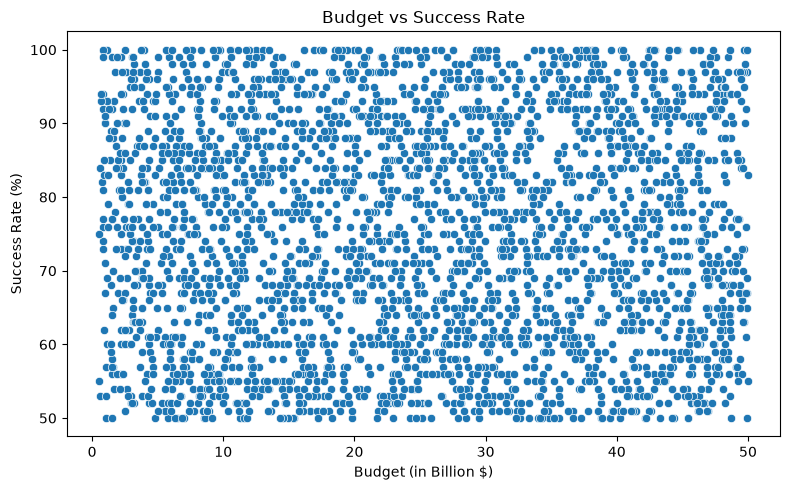

In [37]:
# Step 8.5.1: Budget vs Success Rate

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Budget (in Billion $)",
    y="Success Rate (%)"
)

plt.title("Budget vs Success Rate")
plt.xlabel("Budget (in Billion $)")
plt.ylabel("Success Rate (%)")

plt.tight_layout()
plt.show()

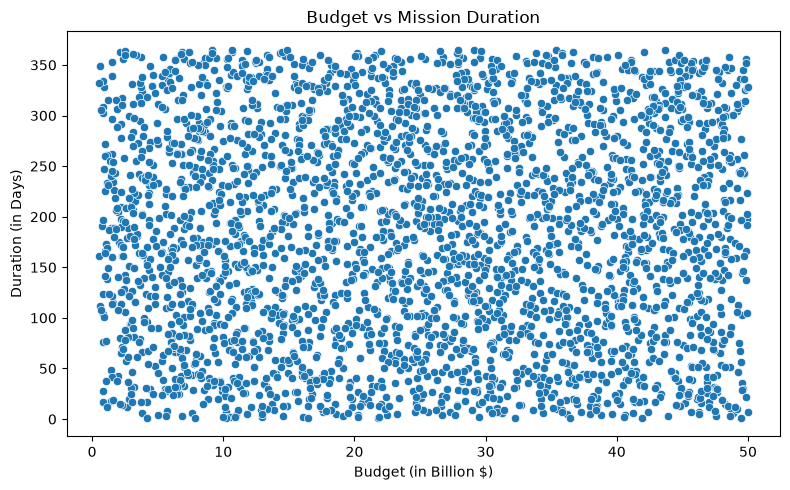

In [38]:
# Step 8.5.2: Budget vs Mission Duration

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Budget (in Billion $)",
    y="Duration (in Days)"
)

plt.title("Budget vs Mission Duration")
plt.xlabel("Budget (in Billion $)")
plt.ylabel("Duration (in Days)")

plt.tight_layout()
plt.show()

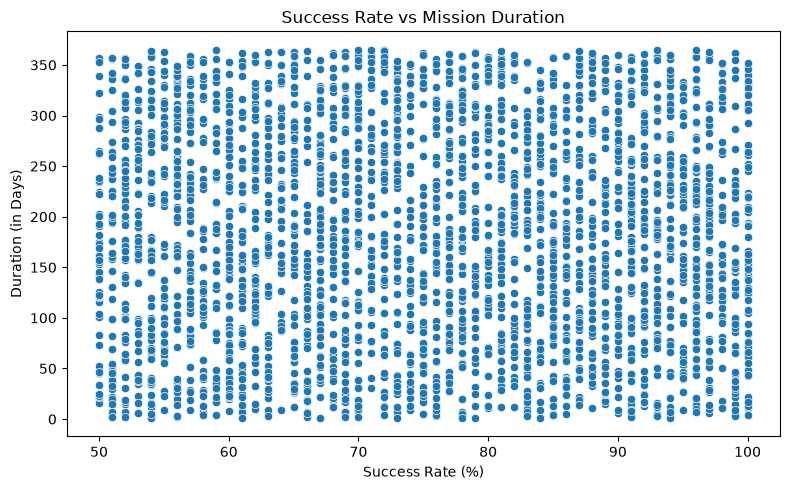

In [39]:
 
# Step 8.5.3: Success Rate vs Mission Duration

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Success Rate (%)",
    y="Duration (in Days)"
)

plt.title("Success Rate vs Mission Duration")
plt.xlabel("Success Rate (%)")
plt.ylabel("Duration (in Days)")

plt.tight_layout()
plt.show()


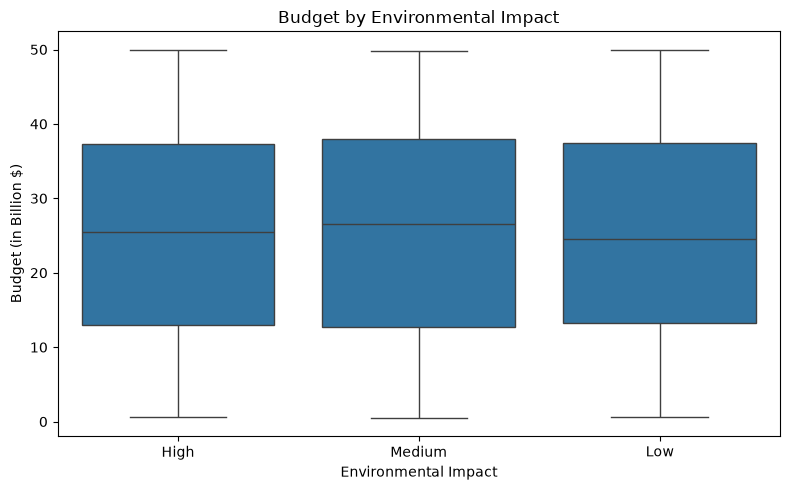

In [40]:
# Step 8.6.1: Budget vs Environmental Impact

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Environmental Impact",
    y="Budget (in Billion $)",
    order=["High", "Medium", "Low"]
)

plt.title("Budget by Environmental Impact")
plt.xlabel("Environmental Impact")
plt.ylabel("Budget (in Billion $)")

plt.tight_layout()
plt.show()

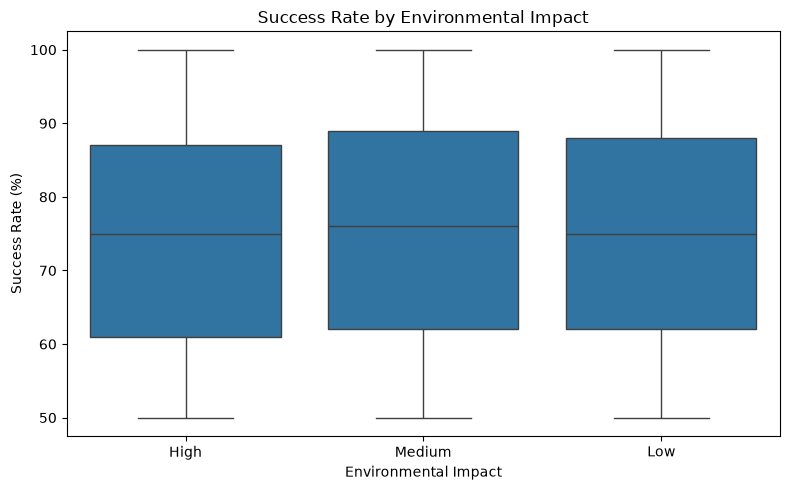

In [41]:
# Step 8.6.2: Success Rate vs Environmental Impact

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Environmental Impact",
    y="Success Rate (%)",
    order=["High", "Medium", "Low"]
)

plt.title("Success Rate by Environmental Impact")
plt.xlabel("Environmental Impact")
plt.ylabel("Success Rate (%)")

plt.tight_layout()
plt.show()

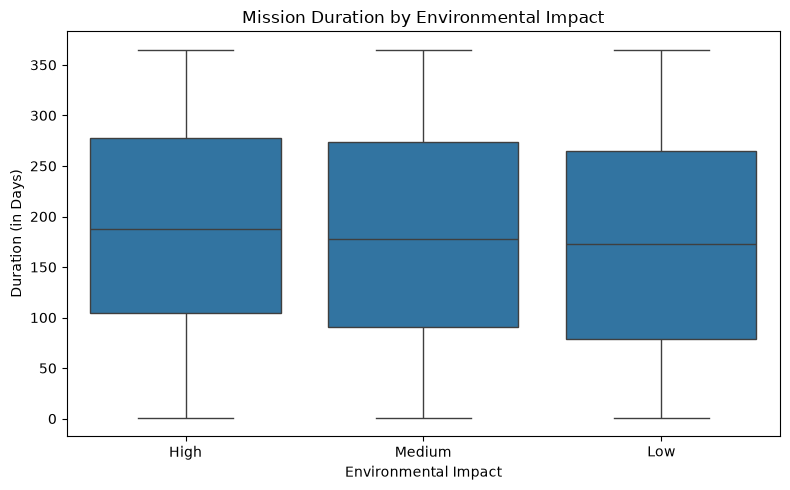

In [42]:
# Step 8.6.3: Mission Duration vs Environmental Impact

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Environmental Impact",
    y="Duration (in Days)",
    order=["High", "Medium", "Low"]
)

plt.title("Mission Duration by Environmental Impact")
plt.xlabel("Environmental Impact")
plt.ylabel("Duration (in Days)")

plt.tight_layout()
plt.show()

Dataset loaded successfully!
(3000, 12)


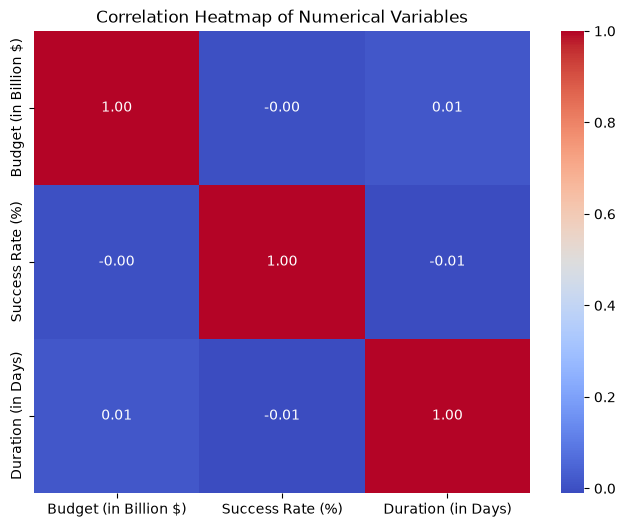

In [43]:
# Step 9: Correlation Analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/Global_Space_Exploration_Dataset.csv")

print("Dataset loaded successfully!")
print(df.shape)

numeric_df = df[
    ["Budget (in Billion $)", "Success Rate (%)", "Duration (in Days)"]
]

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

In [44]:
# Step 10: Feature and Target Selection

X = df.drop(columns=["Environmental Impact"])
y = df["Environmental Impact"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nTarget categories:")
print(y.unique())

Features (X) shape: (3000, 11)
Target (y) shape: (3000,)

Target categories:
<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str


In [45]:
# Step 11: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2400, 11)
X_test shape: (600, 11)
y_train shape: (2400,)
y_test shape: (600,)


In [46]:
# Step 12: Data Preprocessing
# Step 12.1: Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['Year', 'Budget (in Billion $)', 'Success Rate (%)', 'Duration (in Days)']

Categorical features:
['Country', 'Mission Name', 'Mission Type', 'Launch Site', 'Satellite Type', 'Technology Used', 'Collaborating Countries']

Number of numerical features: 4
Number of categorical features: 7


In [47]:
# Step 12.2: Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [48]:
# Step 12.3: Apply preprocessing

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Preprocessing completed successfully.")

Training data shape: (2400, 5201)
Testing data shape: (600, 5201)
Preprocessing completed successfully.


In [49]:
# Step 13.1: Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

y_pred_logistic = logistic_model.predict(X_test_processed)

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 35.5 %


In [50]:
# Step 13.2: Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train_processed, y_train)

y_pred_tree = decision_tree_model.predict(X_test_processed)

tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:",
      round(tree_accuracy * 100, 2), "%")

Decision Tree Accuracy: 33.67 %


In [51]:
# Step 13.3: Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_processed, y_train)

y_pred_rf = random_forest_model.predict(X_test_processed)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 33.67 %


In [52]:
# Step 13.4: K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_processed, y_train)

y_pred_knn = knn_model.predict(X_test_processed)

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 34.5 %


In [53]:
# Step 14: Compare Model Accuracies

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN"
    ],
    "Accuracy (%)": [
        logistic_accuracy * 100,
        tree_accuracy * 100,
        rf_accuracy * 100,
        knn_accuracy * 100
    ]
})

model_comparison = model_comparison.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print(model_comparison)

                 Model  Accuracy (%)
0  Logistic Regression     35.500000
1                  KNN     34.500000
2        Decision Tree     33.666667
3        Random Forest     33.666667


In [54]:
# Step 15: Classification Report

from sklearn.metrics import classification_report

print("Classification Report: Logistic Regression\n")

print(classification_report(
    y_test,
    y_pred_logistic,
    labels=["High", "Medium", "Low"],
    zero_division=0
))

Classification Report: Logistic Regression

              precision    recall  f1-score   support

        High       0.37      0.32      0.34       192
      Medium       0.36      0.37      0.36       206
         Low       0.34      0.38      0.36       202

    accuracy                           0.35       600
   macro avg       0.36      0.35      0.35       600
weighted avg       0.36      0.35      0.35       600



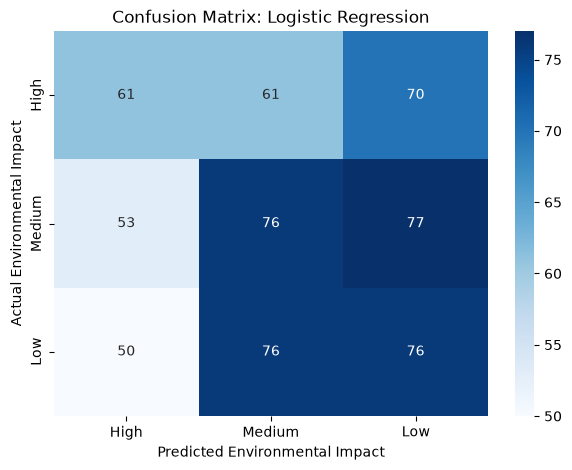

In [55]:
# Step 16: Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class_order = ["High", "Medium", "Low"]

cm = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=class_order
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order
)

plt.title("Confusion Matrix: Logistic Regression")
plt.xlabel("Predicted Environmental Impact")
plt.ylabel("Actual Environmental Impact")
plt.show()

In [56]:
# Step 17: Feature Importance and Interpretation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Get the names of the processed features
feature_names = preprocessor.get_feature_names_out()

# Get model coefficients for each class
coefficients = logistic_model.coef_

# Calculate mean absolute coefficient magnitude
importance = np.mean(np.abs(coefficients), axis=0)

# Create a feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
top_features = feature_importance.head(15)

print(top_features.to_string(index=False))

                                           Feature  Importance
        cat__Collaborating Countries_France, India    0.705890
          cat__Collaborating Countries_Israel, UAE    0.616950
        cat__Collaborating Countries_Japan, Israel    0.583575
          cat__Collaborating Countries_Russia, UAE    0.577792
       cat__Collaborating Countries_Germany, China    0.542174
                       cat__Launch Site_West James    0.535432
cat__Collaborating Countries_India, Japan, Germany    0.524428
    cat__Collaborating Countries_India, UAE, Japan    0.513287
            cat__Collaborating Countries_UK, China    0.510494
                      cat__Launch Site_Jeffreyfort    0.506600
         cat__Collaborating Countries_Germany, USA    0.505828
                      cat__Launch Site_New Richard    0.503174
  cat__Collaborating Countries_France, Israel, UAE    0.500841
                      cat__Launch Site_Ashleymouth    0.498710
              cat__Collaborating Countries_USA, UK    0

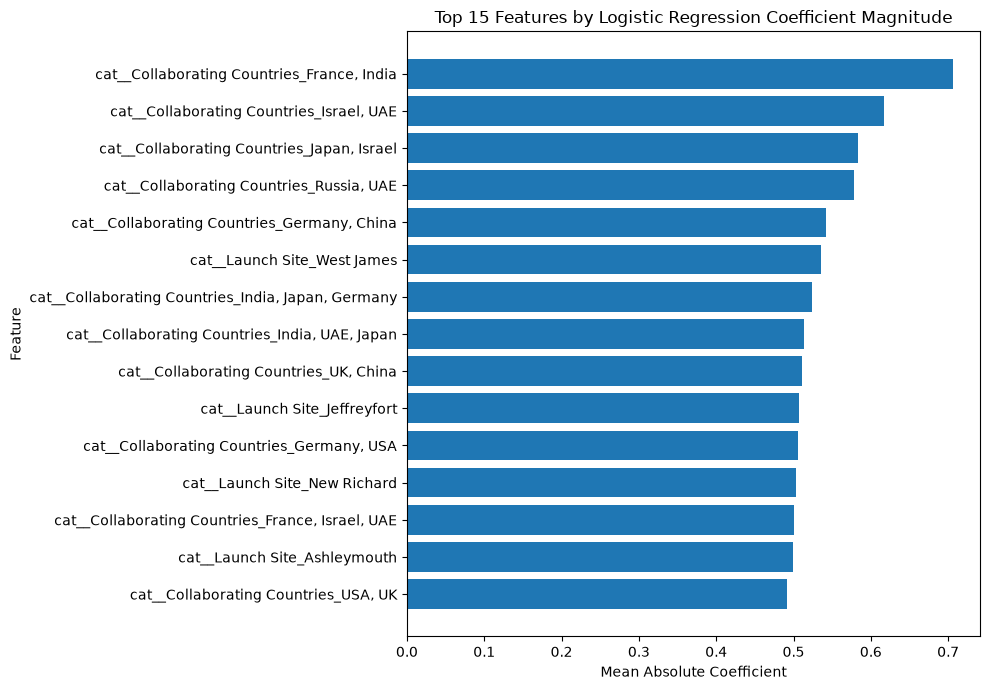

In [57]:
# Step 17.2: Visualize Feature Importance

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Features by Logistic Regression Coefficient Magnitude")
plt.xlabel("Mean Absolute Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Step 18: Findings and Results Discussion

The Global Space Missions dataset contains 3,000 records and 12 columns. Exploratory Data Analysis was conducted to examine mission characteristics, numerical distributions, outliers, and relationships between variables.

Correlation analysis showed negligible linear relationships among Budget, Success Rate, and Mission Duration, with correlation coefficients ranging approximately from −0.01 to 0.01.

Four machine-learning models were evaluated using an 80:20 train-test split. Logistic Regression achieved the highest test accuracy of 35.50%, followed by K-Nearest Neighbors at 34.50%. Decision Tree and Random Forest each achieved 33.67% accuracy.

The Logistic Regression model achieved an overall F1-score of approximately 0.35. Its confusion matrix showed considerable misclassification among the High, Medium, and Low environmental-impact categories.

Feature-coefficient analysis identified several encoded Collaborating Countries and Launch Site categories with relatively large coefficient magnitudes. However, these results describe the model's learned patterns and do not establish causation.

Overall, the tested models showed limited predictive performance. Further work is needed to improve feature selection, evaluate alternative models, and investigate the reasons for the low accuracy.

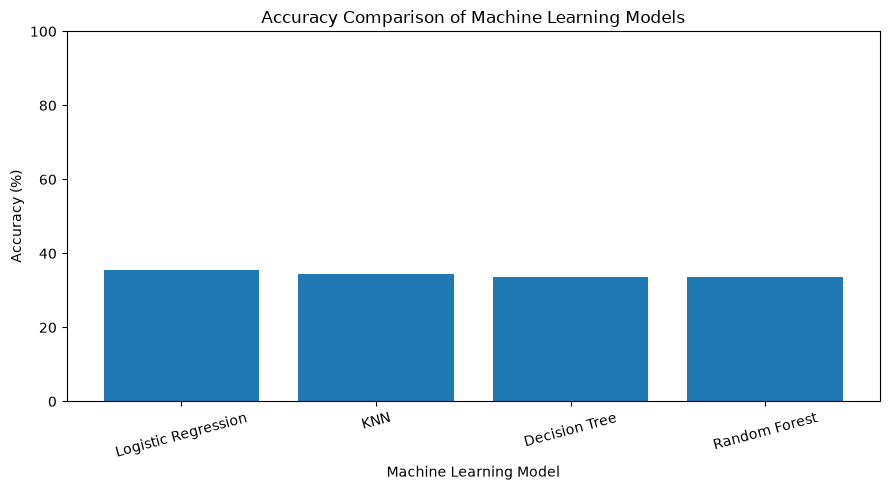

In [58]:
# Step 18.2: Model Accuracy Comparison

plt.figure(figsize=(9, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy (%)"]
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Step 18.3: Model Performance Interpretation

The model accuracy comparison shows that Logistic Regression achieved the highest accuracy of 35.50%, followed by K-Nearest Neighbors at 34.50%. Decision Tree and Random Forest both achieved 33.67%.

Although Logistic Regression performed best among the four tested models, its accuracy remains limited. The results indicate that the current models have difficulty distinguishing between the High, Medium, and Low environmental-impact categories. Further improvements in feature selection, data quality, and model tuning may be required.

# Step 19: Conclusion

The project, *Global Space Missions: Environmental Impact Analysis and Prediction*, focused on analyzing space-mission data and developing machine-learning models to predict environmental impact categories.

The dataset consisted of 3,000 records and 12 columns. Exploratory Data Analysis was performed to understand mission characteristics, numerical distributions, outliers, and relationships among variables. Correlation analysis indicated negligible linear relationships among Budget, Success Rate, and Mission Duration.

Four machine-learning algorithms were evaluated: Logistic Regression, Decision Tree, Random Forest, and K-Nearest Neighbors (KNN). Logistic Regression achieved the highest test accuracy of 35.50%, followed by KNN at 34.50%. Decision Tree and Random Forest each achieved 33.67%.

Feature-coefficient analysis highlighted several encoded Collaborating Countries and Launch Site categories with relatively large coefficient magnitudes. However, the overall predictive performance was limited, and the results do not establish causal relationships between these features and environmental impact.

In conclusion, this project demonstrated the application of data analysis, visualization, preprocessing, and supervised machine learning to a space-mission dataset. The low model accuracy indicates that further investigation, improved feature selection, model tuning, and validation of the dataset would be necessary before using the predictions for practical decision-making.